# Notebook B – Hotel booking cancellation: expanding-window time-ordered evaluation
Each model is trained only on bookings arriving before a cut-off date and tested on the next period. Three cut-offs give three future test periods (Jul–Dec 2016, Jan–Apr 2017, May–Aug 2017). Hyperparameters are chosen inside each training period on its latest 10%.

In [1]:
# Cell 0 (Colab only): install libraries, then upload hotel_bookings.csv using the Files panel
!pip install -q xgboost lightgbm imbalanced-learn statsmodels shap


## 1. Data preparation

In [2]:
# Cell 1: Imports and settings
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import xgboost as xgb
import lightgbm as lgb
import shap
from scipy.stats import friedmanchisquare, spearmanr
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)
from imblearn.over_sampling import SMOTE
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import (Input, Conv1D, Dense, Dropout, Flatten,
                                     BatchNormalization, Concatenate, Reshape)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings('ignore')
SEED = 42
N_FOLDS = 5
EPOCHS = 50
N_CONFIGS_GBM = 10      # random-search configurations per boosting model
N_CONFIGS_DL = 4        # random-search configurations per neural network
DATA_PATH = 'hotel_bookings.csv'
OUT_DIR = 'results_B'
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
GPU = len(tf.config.list_physical_devices('GPU')) > 0
XGB_DEVICE = 'cuda' if GPU else 'cpu'
print('TensorFlow', tf.__version__, '| XGBoost', xgb.__version__, '| LightGBM', lgb.__version__, '| SHAP', shap.__version__)
print('GPU available:', GPU, '| XGBoost device:', XGB_DEVICE)


TensorFlow 2.21.0 | XGBoost 3.4.1 | LightGBM 4.6.0 | SHAP 0.52.0
GPU available: True | XGBoost device: cuda


In [3]:
# Cell 2: Load data and remove exact duplicates
df_raw = pd.read_csv(DATA_PATH)
n_raw = len(df_raw)
n_dup = df_raw.duplicated().sum()
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f'Raw records:         {n_raw:,}')
print(f'Exact duplicates:    {n_dup:,} ({n_dup / n_raw:.1%})')
print(f'Records after dedup: {len(df):,}')


Raw records:         119,390
Exact duplicates:    31,994 (26.8%)
Records after dedup: 87,396


In [4]:
# Cell 3: Remove leakage columns, handle missing values, engineer features
leak_cols = ['reservation_status', 'reservation_status_date', 'assigned_room_type',
             'booking_changes', 'agent', 'company']
df = df.drop(columns=leak_cols)
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
country_counts = df['country'].value_counts()
rare_countries = country_counts[country_counts < 100].index
df.loc[df['country'].isin(rare_countries), 'country'] = 'Other'
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['was_waitlisted'] = (df['days_in_waiting_list'] > 0).astype(int)
df['is_family'] = ((df['children'] + df['babies']) > 0).astype(int)
df = df[df['total_guests'] > 0].reset_index(drop=True)
arrival_date = pd.to_datetime(df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-' +
                              df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
print('Shape after cleaning:', df.shape)


Shape after cleaning: (87230, 30)


In [5]:
# Cell 4: Encode categorical features
cat_cols = ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
            'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
y = df['is_canceled'].values
X = df.drop(columns=['is_canceled'])
num_cols = [c for c in X.columns if c not in cat_cols]
X = pd.get_dummies(X, columns=cat_cols, drop_first=False, dtype=float).astype('float32')
feature_names = X.columns.tolist()
print('Total features after one-hot encoding:', X.shape[1], '| Class counts:', np.bincount(y))


Total features after one-hot encoding: 105 | Class counts: [63221 24009]


In [6]:
# Cell 5: Random-search configurations (drawn once, the same for every fold)
rng = np.random.RandomState(SEED)
lr_grid = [0.01, 0.1, 1.0, 10.0]
xgb_configs = [{'max_depth': int(rng.choice([4, 6, 8, 10])), 'learning_rate': float(rng.choice([0.03, 0.05, 0.1])),
                'subsample': float(rng.choice([0.7, 0.8, 1.0])), 'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
                'min_child_weight': int(rng.choice([1, 3, 5])), 'reg_lambda': float(rng.choice([0.5, 1.0, 5.0]))}
               for _ in range(N_CONFIGS_GBM)]
lgb_configs = [{'num_leaves': int(rng.choice([31, 63, 127, 255])), 'learning_rate': float(rng.choice([0.03, 0.05, 0.1])),
                'min_child_samples': int(rng.choice([10, 20, 50])), 'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
                'subsample': float(rng.choice([0.7, 0.8, 1.0])), 'reg_lambda': float(rng.choice([0.0, 1.0, 5.0]))}
               for _ in range(N_CONFIGS_GBM)]
dl_configs = [{'learning_rate': float(rng.choice([1e-3, 5e-4, 2e-4])), 'dropout': float(rng.choice([0.2, 0.3, 0.4])),
               'width': float(rng.choice([0.5, 1.0])), 'batch_size': int(rng.choice([256, 512]))}
              for _ in range(N_CONFIGS_DL)]
pd.DataFrame(xgb_configs).to_csv(f'{OUT_DIR}/search_space_xgboost.csv', index_label='config')
pd.DataFrame(lgb_configs).to_csv(f'{OUT_DIR}/search_space_lightgbm.csv', index_label='config')
pd.DataFrame(dl_configs).to_csv(f'{OUT_DIR}/search_space_neural.csv', index_label='config')
print(f'{len(lr_grid)} logistic regression values, {N_CONFIGS_GBM} XGBoost, {N_CONFIGS_GBM} LightGBM and {N_CONFIGS_DL} neural-network configurations')


4 logistic regression values, 10 XGBoost, 10 LightGBM and 4 neural-network configurations


In [7]:
# Cell 6: Prepare the 3 expanding windows (identical for every model)
# Arrival year is dropped: a model cannot learn anything useful about a year it has never seen.
X_t = X.drop(columns=['arrival_date_year'])
num_cols_t = [c for c in num_cols if c != 'arrival_date_year']
feature_names_t = X_t.columns.tolist()
windows = [('2016-07-01', '2017-01-01'), ('2017-01-01', '2017-05-01'), ('2017-05-01', '2017-09-01')]
split_names, split_train_X, split_train_y, split_val_X, split_val_y = [], [], [], [], []
split_test_X, split_test_y, split_test_idx = [], [], []
window_rows = []
for start, end in windows:
    tr_mask = (arrival_date < start).values
    te_mask = ((arrival_date >= start) & (arrival_date < end)).values
    X_tr_df = X_t[tr_mask].copy()
    X_te_df = X_t[te_mask].copy()
    y_tr, y_te = y[tr_mask], y[te_mask]
    upper = X_tr_df[num_cols_t].quantile(0.99)
    X_tr_df[num_cols_t] = X_tr_df[num_cols_t].clip(upper=upper, axis=1)
    X_te_df[num_cols_t] = X_te_df[num_cols_t].clip(upper=upper, axis=1)
    # validation = the latest 10% of the training period (by arrival date)
    cut = arrival_date[tr_mask].quantile(0.9)
    val_mask = (arrival_date[tr_mask] > cut).values
    X_in_df, X_val_df = X_tr_df[~val_mask].copy(), X_tr_df[val_mask].copy()
    y_in, y_val = y_tr[~val_mask], y_tr[val_mask]
    scaler = MinMaxScaler()
    X_in_df[num_cols_t] = scaler.fit_transform(X_in_df[num_cols_t])
    X_val_df[num_cols_t] = scaler.transform(X_val_df[num_cols_t])
    X_te_df[num_cols_t] = scaler.transform(X_te_df[num_cols_t])
    X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_in_df.values, y_in)
    name = f'Test {pd.Timestamp(start):%b %Y}–{pd.Timestamp(end) - pd.Timedelta(days=1):%b %Y}'
    split_names.append(name)
    split_train_X.append(X_sm.astype('float32'))
    split_train_y.append(y_sm)
    split_val_X.append(X_val_df.values.astype('float32'))
    split_val_y.append(y_val)
    split_test_X.append(X_te_df.values.astype('float32'))
    split_test_y.append(y_te)
    split_test_idx.append(np.where(te_mask)[0])
    window_rows.append({'Window': name, 'Training arrivals': f'{arrival_date[tr_mask].min():%b %Y}–{arrival_date[tr_mask].max():%b %Y}',
                        'Training bookings': int(tr_mask.sum()), 'Training cancellation rate': round(y_tr.mean(), 3),
                        'Test bookings': int(te_mask.sum()), 'Test cancellation rate': round(y_te.mean(), 3)})
    print(f'{name}: train {tr_mask.sum():,} (cancel {y_tr.mean():.3f}) | val {len(y_val):,} | test {te_mask.sum():,} (cancel {y_te.mean():.3f})')
window_df = pd.DataFrame(window_rows)
window_df.to_csv(f'{OUT_DIR}/table_windows.csv', index=False)
window_df


Test Jul 2016–Dec 2016: train 32,817 (cancel 0.222) | val 3,249 | test 22,780 (cancel 0.291)
Test Jan 2017–Apr 2017: train 55,597 (cancel 0.250) | val 5,542 | test 13,916 (cancel 0.284)
Test May 2017–Aug 2017: train 69,513 (cancel 0.257) | val 6,941 | test 17,717 (cancel 0.347)


,Window,Training arrivals,Training bookings,Training cancellation rate,Test bookings,Test cancellation rate
0,Test Jul 2016–Dec 2016,Jul 2015–Jun 2016,32817,0.222,22780,0.291
1,Test Jan 2017–Apr 2017,Jul 2015–Dec 2016,55597,0.250,13916,0.284
2,Test May 2017–Aug 2017,Jul 2015–Apr 2017,69513,0.257,17717,0.347


In [8]:
# Cell 7: Shared containers
model_names = ['Logistic Regression', '1D CNN', 'DNN', 'CNN+DNN Hybrid', 'XGBoost', 'LightGBM']
N_SPLITS = len(split_names)
n_feat = split_train_X[0].shape[1]
oof_proba = {m: np.full(len(y), np.nan) for m in model_names}
results_rows = []
histories = {}


## 2. Logistic Regression

In [9]:
# Cell 8: Train Logistic Regression (hyperparameter search inside each window)
m = 'Logistic Regression'
results_rows = [r for r in results_rows if r['Model'] != m]
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time = -1.0, None, None, 0.0, 0.0
    for ci, C in enumerate(lr_grid):
        t0 = time.time()
        lr_model = LogisticRegression(C=C, max_iter=2000, random_state=SEED)
        lr_model.fit(split_train_X[s], split_train_y[s])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], lr_model.predict_proba(split_val_X[s])[:, 1])
        if val_auc > best_auc:
            best_auc, best_cfg, best_time = val_auc, ci, fit_time
            best_p = lr_model.predict_proba(split_test_X[s])[:, 1]
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Test Jul 2016–Dec 2016: config=1  val AUC=0.8378  test Acc=0.7570  F1=0.5762  AUC=0.7998  search=9s
Test Jan 2017–Apr 2017: config=0  val AUC=0.7825  test Acc=0.7396  F1=0.5879  AUC=0.7992  search=15s
Test May 2017–Aug 2017: config=0  val AUC=0.8226  test Acc=0.7062  F1=0.6494  AUC=0.8024  search=14s


===== Logistic Regression: results per split =====
                 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Test Jul 2016–Dec 2016    0.7570     0.5844  0.5683 0.5762   0.7998  0.6144                         2.3788           8.9876              1              0.8378
Test Jan 2017–Apr 2017    0.7396     0.5345  0.6531 0.5879   0.7992  0.5993                         2.5663          15.4253              0              0.7825
Test May 2017–Aug 2017    0.7062     0.5542  0.7842 0.6494   0.8024  0.6701                         2.7463          13.6834              0              0.8226

Mean ± std:
  Accuracy   0.7343 ± 0.0258
  Precision  0.5577 ± 0.0251
  Recall     0.6685 ± 0.1088
  F1         0.6045 ± 0.0393
  ROC-AUC    0.8005 ± 0.0017
  PR-AUC     0.6280 ± 0.0373

===== Logistic Regression: classification report (pooled test predictions) =====
              precision    recall  f1-score 

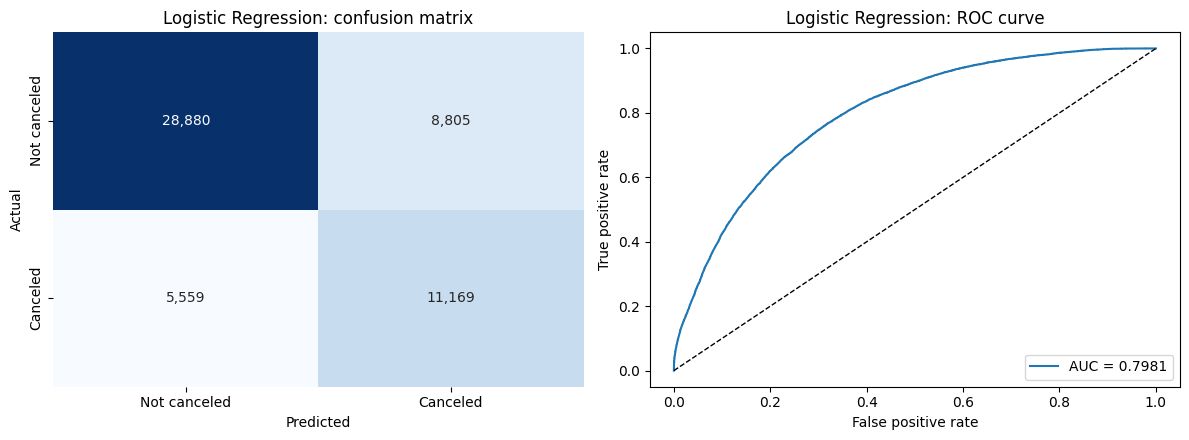

In [10]:
# Cell 9: Evaluate Logistic Regression
m = 'Logistic Regression'
tag = 'logreg'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax_cm, ax_roc = axes[0], axes[1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 3. 1D CNN

In [11]:
# Cell 10: Train 1D CNN (hyperparameter search inside each window)
m = '1D CNN'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(dl_configs):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED + s)
        w, dr = c['width'], c['dropout']
        net = Sequential([
            Input(shape=(n_feat, 1)),
            Conv1D(int(64 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4)),
            BatchNormalization(), Dropout(dr),
            Conv1D(int(128 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4)),
            BatchNormalization(), Dropout(dr),
            Flatten(),
            Dense(int(64 * w), activation='relu', kernel_regularizer=l2(1e-4)), Dropout(dr),
            Dense(1, activation='sigmoid')
        ])
        net.compile(optimizer=Adam(learning_rate=c['learning_rate']), loss='binary_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        h = net.fit(split_train_X[s][..., None], split_train_y[s], validation_data=(split_val_X[s][..., None], split_val_y[s]),
                    epochs=EPOCHS, batch_size=c['batch_size'], verbose=0,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                               ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], net.predict(split_val_X[s][..., None], batch_size=2048, verbose=0).ravel())
        if val_auc > best_auc:
            best_auc, best_cfg, best_time, best_hist = val_auc, ci, fit_time, h.history
            best_p = net.predict(split_test_X[s][..., None], batch_size=2048, verbose=0).ravel()
            if s == 0:
                net.save(f'{OUT_DIR}/cnn_fold1_best.keras')
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Test Jul 2016–Dec 2016: config=0  val AUC=0.9158  test Acc=0.7446  F1=0.4542  AUC=0.7733  search=123s
Test Jan 2017–Apr 2017: config=0  val AUC=0.8277  test Acc=0.7238  F1=0.5988  AUC=0.8137  search=120s
Test May 2017–Aug 2017: config=3  val AUC=0.8316  test Acc=0.7110  F1=0.6424  AUC=0.7989  search=143s


===== 1D CNN: results per split =====
                 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Test Jul 2016–Dec 2016    0.7446     0.5994  0.3656 0.4542   0.7733  0.5803                        39.9038         122.6507              0              0.9158
Test Jan 2017–Apr 2017    0.7238     0.5101  0.7249 0.5988   0.8137  0.6390                        27.1881         119.7647              0              0.8277
Test May 2017–Aug 2017    0.7110     0.5628  0.7482 0.6424   0.7989  0.6563                        31.3989         142.5064              3              0.8316

Mean ± std:
  Accuracy   0.7264 ± 0.0170
  Precision  0.5575 ± 0.0449
  Recall     0.6129 ± 0.2145
  F1         0.5651 ± 0.0985
  ROC-AUC    0.7953 ± 0.0205
  PR-AUC     0.6252 ± 0.0399

===== 1D CNN: classification report (pooled test predictions) =====
              precision    recall  f1-score   support

Not canceled   

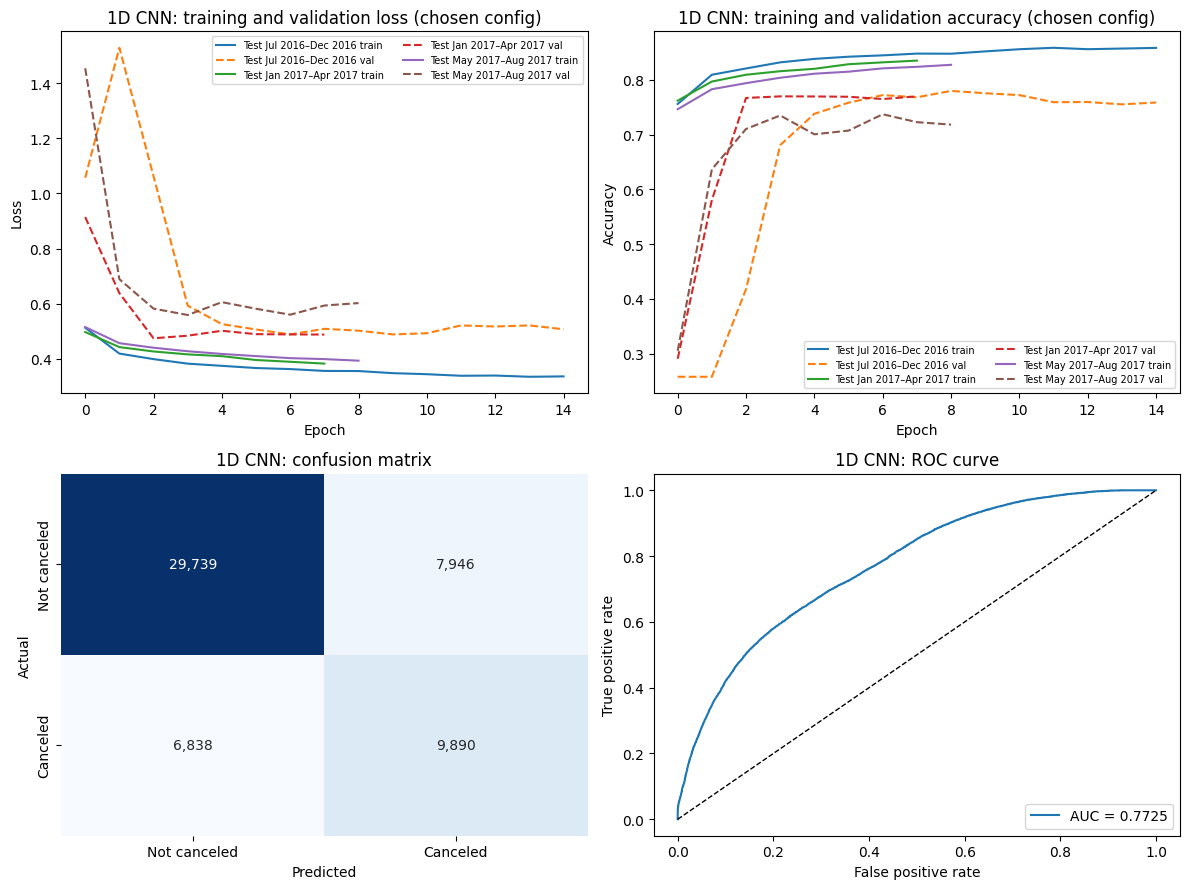

In [12]:
# Cell 11: Evaluate 1D CNN
m = '1D CNN'
tag = 'cnn'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, hist in enumerate(histories[m]):
    axes[0, 0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0, 0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
    axes[0, 1].plot(hist['accuracy'], label=f'{split_names[k]} train')
    axes[0, 1].plot(hist['val_accuracy'], '--', label=f'{split_names[k]} val')
axes[0, 0].set_title(f'{m}: training and validation loss (chosen config)')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 1].set_title(f'{m}: training and validation accuracy (chosen config)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1, 0], axes[1, 1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 4. DNN

In [13]:
# Cell 12: Train DNN (hyperparameter search inside each window)
m = 'DNN'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(dl_configs):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED + s)
        w, dr = c['width'], c['dropout']
        net = Sequential([
            Input(shape=(n_feat,)),
            Dense(int(512 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(), Dropout(dr),
            Dense(int(256 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(), Dropout(dr),
            Dense(int(128 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(), Dropout(dr),
            Dense(int(64 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(),
            Dense(1, activation='sigmoid')
        ])
        net.compile(optimizer=Adam(learning_rate=c['learning_rate']), loss='binary_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        h = net.fit(split_train_X[s], split_train_y[s], validation_data=(split_val_X[s], split_val_y[s]),
                    epochs=EPOCHS, batch_size=c['batch_size'], verbose=0,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
                               ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], net.predict(split_val_X[s], batch_size=2048, verbose=0).ravel())
        if val_auc > best_auc:
            best_auc, best_cfg, best_time, best_hist = val_auc, ci, fit_time, h.history
            best_p = net.predict(split_test_X[s], batch_size=2048, verbose=0).ravel()
            if s == 0:
                net.save(f'{OUT_DIR}/dnn_fold1_best.keras')
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Test Jul 2016–Dec 2016: config=0  val AUC=0.9005  test Acc=0.7260  F1=0.3796  AUC=0.7249  search=105s
Test Jan 2017–Apr 2017: config=2  val AUC=0.8019  test Acc=0.7087  F1=0.5879  AUC=0.7991  search=88s
Test May 2017–Aug 2017: config=1  val AUC=0.8327  test Acc=0.6829  F1=0.6383  AUC=0.7966  search=117s


===== DNN: results per split =====
                 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Test Jul 2016–Dec 2016    0.7260     0.5552  0.2884 0.3796   0.7249  0.5179                        29.4622         104.9050              0              0.9005
Test Jan 2017–Apr 2017    0.7087     0.4918  0.7307 0.5879   0.7991  0.6257                        21.1923          87.8638              2              0.8019
Test May 2017–Aug 2017    0.6829     0.5282  0.8063 0.6383   0.7966  0.6574                        22.0542         117.1777              1              0.8327

Mean ± std:
  Accuracy   0.7059 ± 0.0217
  Precision  0.5251 ± 0.0318
  Recall     0.6085 ± 0.2797
  F1         0.5353 ± 0.1371
  ROC-AUC    0.7735 ± 0.0422
  PR-AUC     0.6003 ± 0.0732

===== DNN: classification report (pooled test predictions) =====
              precision    recall  f1-score   support

Not canceled     0.80

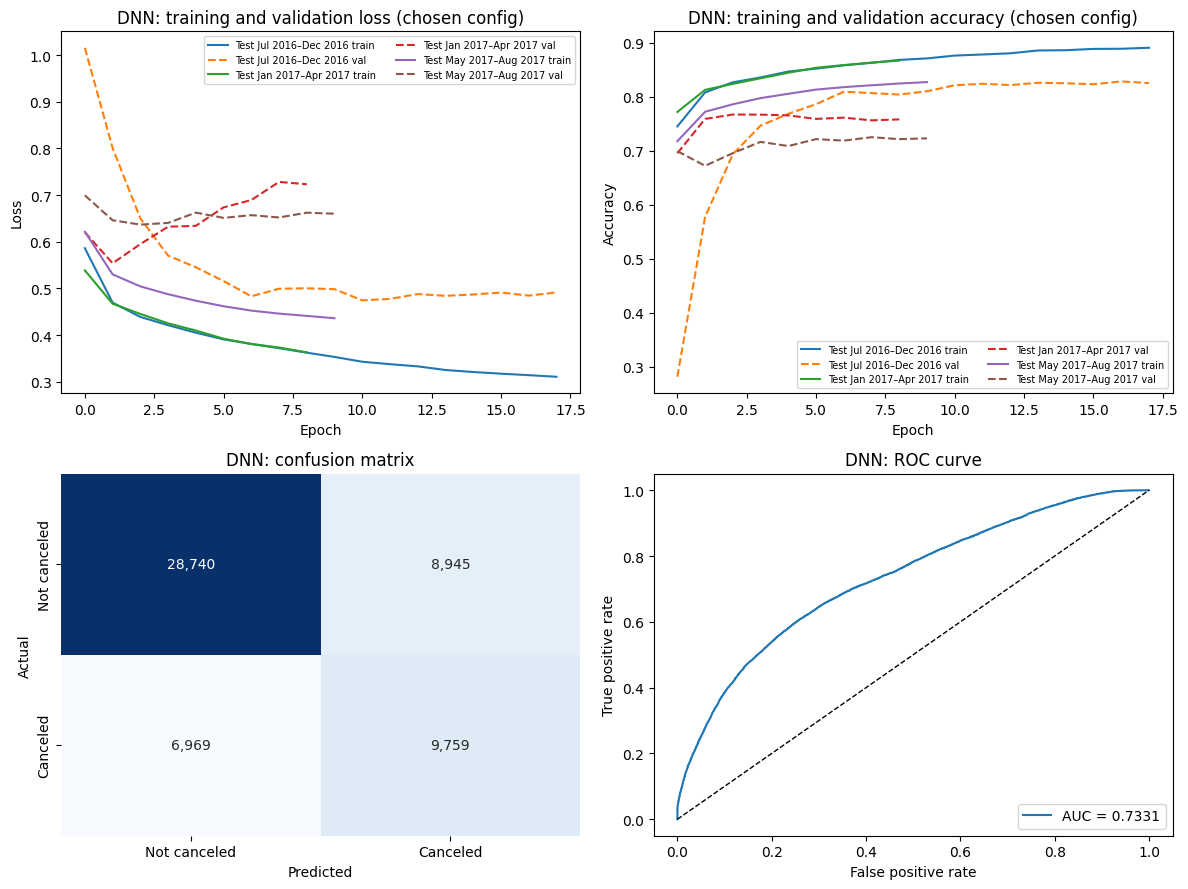

In [14]:
# Cell 13: Evaluate DNN
m = 'DNN'
tag = 'dnn'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, hist in enumerate(histories[m]):
    axes[0, 0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0, 0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
    axes[0, 1].plot(hist['accuracy'], label=f'{split_names[k]} train')
    axes[0, 1].plot(hist['val_accuracy'], '--', label=f'{split_names[k]} val')
axes[0, 0].set_title(f'{m}: training and validation loss (chosen config)')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 1].set_title(f'{m}: training and validation accuracy (chosen config)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1, 0], axes[1, 1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 5. CNN+DNN Hybrid

In [15]:
# Cell 14: Train CNN+DNN Hybrid (hyperparameter search inside each window)
m = 'CNN+DNN Hybrid'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(dl_configs):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED + s)
        w, dr = c['width'], c['dropout']
        inp = Input(shape=(n_feat,))
        cb = Reshape((n_feat, 1))(inp)
        cb = Conv1D(int(64 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4))(cb)
        cb = BatchNormalization()(cb)
        cb = Conv1D(int(128 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4))(cb)
        cb = BatchNormalization()(cb)
        cb = Flatten()(cb)
        cb = Dense(int(128 * w), activation='relu', kernel_regularizer=l2(1e-4))(cb)
        db = Dense(int(256 * w), activation='relu', kernel_regularizer=l2(1e-4))(inp)
        db = BatchNormalization()(db)
        db = Dropout(dr)(db)
        db = Dense(int(128 * w), activation='relu', kernel_regularizer=l2(1e-4))(db)
        hb = Concatenate()([cb, db])
        hb = BatchNormalization()(hb)
        hb = Dropout(dr)(hb)
        hb = Dense(int(64 * w), activation='relu', kernel_regularizer=l2(1e-4))(hb)
        hb = Dropout(dr)(hb)
        out = Dense(1, activation='sigmoid')(hb)
        net = Model(inp, out)
        net.compile(optimizer=Adam(learning_rate=c['learning_rate']), loss='binary_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        h = net.fit(split_train_X[s], split_train_y[s], validation_data=(split_val_X[s], split_val_y[s]),
                    epochs=EPOCHS, batch_size=c['batch_size'], verbose=0,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
                               ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], net.predict(split_val_X[s], batch_size=2048, verbose=0).ravel())
        if val_auc > best_auc:
            best_auc, best_cfg, best_time, best_hist = val_auc, ci, fit_time, h.history
            best_p = net.predict(split_test_X[s], batch_size=2048, verbose=0).ravel()
            if s == 0:
                net.save(f'{OUT_DIR}/hybrid_fold1_best.keras')
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Test Jul 2016–Dec 2016: config=0  val AUC=0.9145  test Acc=0.7362  F1=0.2808  AUC=0.7448  search=197s
Test Jan 2017–Apr 2017: config=0  val AUC=0.8184  test Acc=0.7111  F1=0.6046  AUC=0.8111  search=185s
Test May 2017–Aug 2017: config=0  val AUC=0.8377  test Acc=0.7423  F1=0.6207  AUC=0.8016  search=199s


===== CNN+DNN Hybrid: results per split =====
                 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Test Jul 2016–Dec 2016    0.7362     0.6765  0.1771 0.2808   0.7448  0.5368                        68.9099         196.8663              0              0.9145
Test Jan 2017–Apr 2017    0.7111     0.4950  0.7767 0.6046   0.8111  0.6306                        46.2721         185.0231              0              0.8184
Test May 2017–Aug 2017    0.7423     0.6343  0.6077 0.6207   0.8016  0.6665                        48.4136         199.1457              0              0.8377

Mean ± std:
  Accuracy   0.7299 ± 0.0165
  Precision  0.6019 ± 0.0950
  Recall     0.5205 ± 0.3091
  F1         0.5020 ± 0.1918
  ROC-AUC    0.7858 ± 0.0358
  PR-AUC     0.6113 ± 0.0670

===== CNN+DNN Hybrid: classification report (pooled test predictions) =====
              precision    recall  f1-score   support


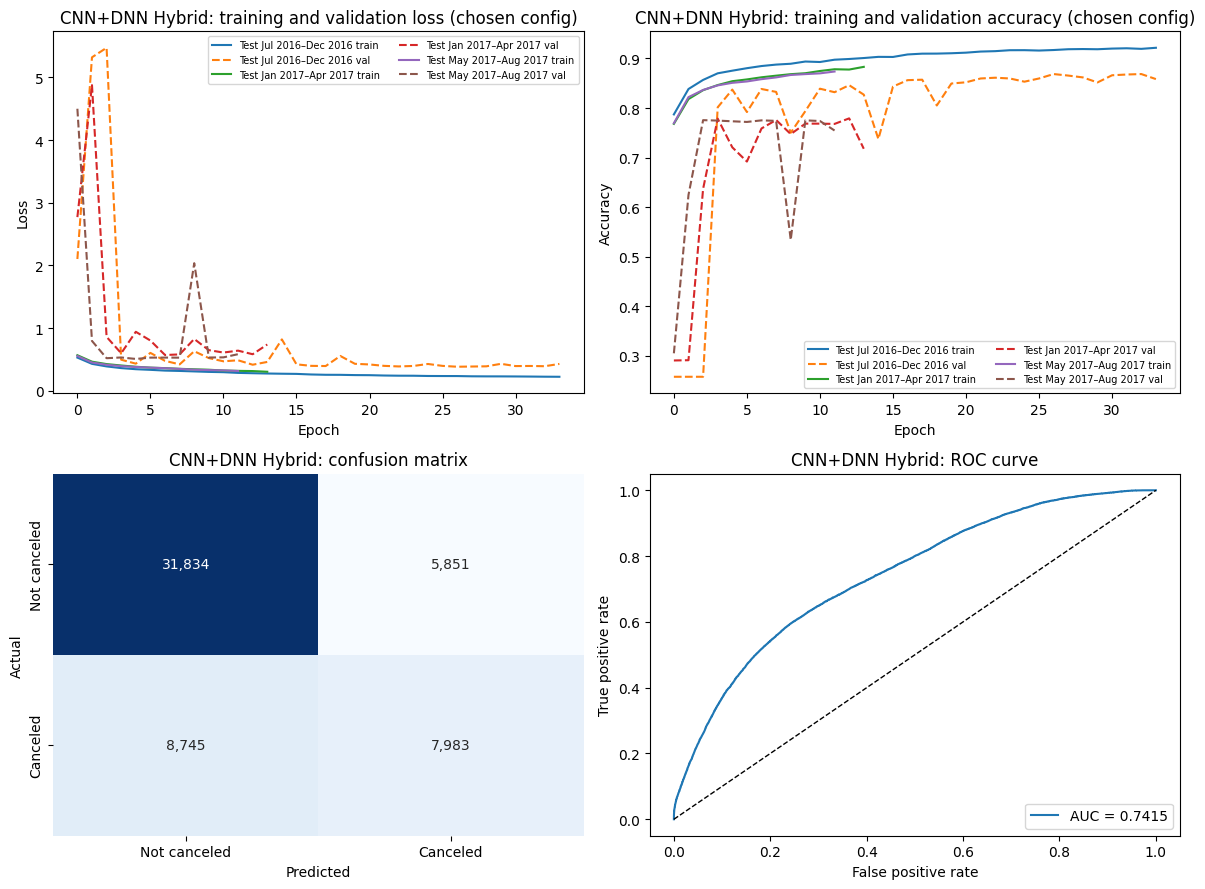

In [16]:
# Cell 15: Evaluate CNN+DNN Hybrid
m = 'CNN+DNN Hybrid'
tag = 'hybrid'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, hist in enumerate(histories[m]):
    axes[0, 0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0, 0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
    axes[0, 1].plot(hist['accuracy'], label=f'{split_names[k]} train')
    axes[0, 1].plot(hist['val_accuracy'], '--', label=f'{split_names[k]} val')
axes[0, 0].set_title(f'{m}: training and validation loss (chosen config)')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 1].set_title(f'{m}: training and validation accuracy (chosen config)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1, 0], axes[1, 1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 6. XGBoost

In [17]:
# Cell 16: Train XGBoost (hyperparameter search inside each window)
m = 'XGBoost'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(xgb_configs):
        xgb_model = xgb.XGBClassifier(n_estimators=2000, eval_metric='logloss', early_stopping_rounds=50,
                                      tree_method='hist', device=XGB_DEVICE, random_state=SEED, n_jobs=-1, **c)
        t0 = time.time()
        xgb_model.fit(split_train_X[s], split_train_y[s],
                      eval_set=[(split_train_X[s], split_train_y[s]), (split_val_X[s], split_val_y[s])], verbose=False)
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], xgb_model.predict_proba(split_val_X[s])[:, 1])
        if val_auc > best_auc:
            ev = xgb_model.evals_result()
            best_auc, best_cfg, best_time = val_auc, ci, fit_time
            best_hist = {'loss': ev['validation_0']['logloss'], 'val_loss': ev['validation_1']['logloss']}
            best_p = xgb_model.predict_proba(split_test_X[s])[:, 1]
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Test Jul 2016–Dec 2016: config=9  val AUC=0.8750  test Acc=0.7401  F1=0.3312  AUC=0.7963  search=10s
Test Jan 2017–Apr 2017: config=1  val AUC=0.8315  test Acc=0.7802  F1=0.5785  AUC=0.8199  search=11s
Test May 2017–Aug 2017: config=9  val AUC=0.8439  test Acc=0.7459  F1=0.5971  AUC=0.8113  search=21s


===== XGBoost: results per split =====
                 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Test Jul 2016–Dec 2016    0.7401     0.6574  0.2214 0.3312   0.7963  0.5984                         1.7362          10.2825              9              0.8750
Test Jan 2017–Apr 2017    0.7802     0.6363  0.5303 0.5785   0.8199  0.6357                         0.9735          10.8584              1              0.8315
Test May 2017–Aug 2017    0.7459     0.6637  0.5426 0.5971   0.8113  0.6715                         1.6377          20.8063              9              0.8439

Mean ± std:
  Accuracy   0.7554 ± 0.0217
  Precision  0.6525 ± 0.0144
  Recall     0.4314 ± 0.1820
  F1         0.5023 ± 0.1484
  ROC-AUC    0.8092 ± 0.0119
  PR-AUC     0.6352 ± 0.0365

===== XGBoost: classification report (pooled test predictions) =====
              precision    recall  f1-score   support

Not canceled 

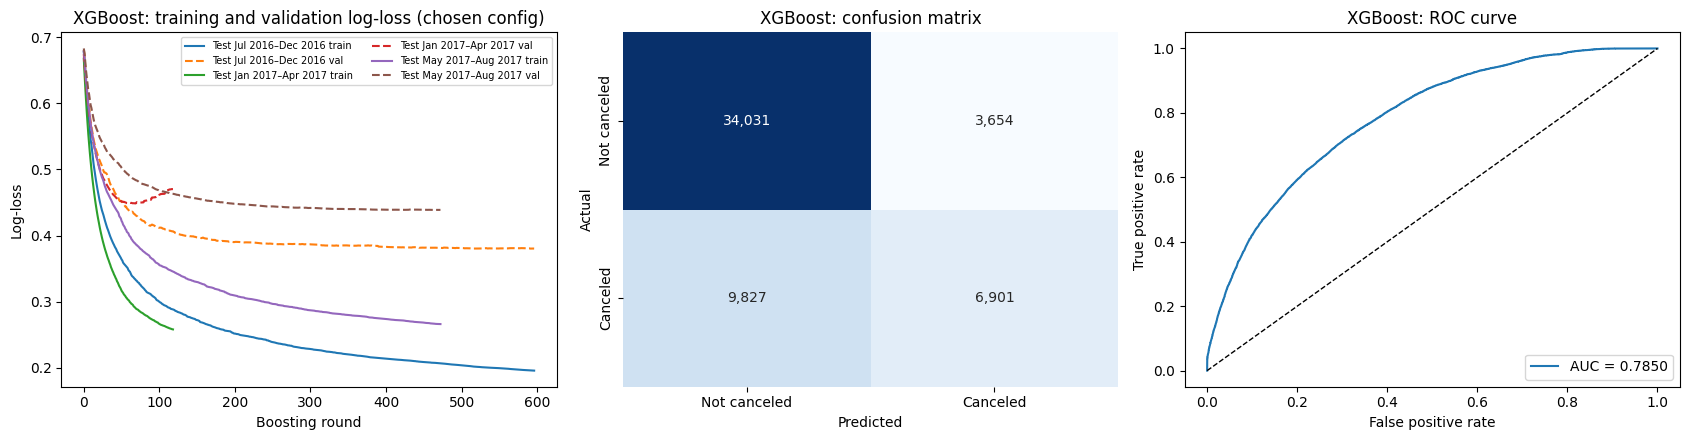

In [18]:
# Cell 17: Evaluate XGBoost
m = 'XGBoost'
tag = 'xgboost'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for k, hist in enumerate(histories[m]):
    axes[0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
axes[0].set_title(f'{m}: training and validation log-loss (chosen config)')
axes[0].set_xlabel('Boosting round')
axes[0].set_ylabel('Log-loss')
axes[0].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1], axes[2]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 7. LightGBM

In [19]:
# Cell 18: Train LightGBM (hyperparameter search inside each window)
m = 'LightGBM'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
lgb_best_models = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist, best_model = -1.0, None, None, 0.0, 0.0, None, None
    for ci, c in enumerate(lgb_configs):
        lgb_model = lgb.LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1, **c)
        t0 = time.time()
        lgb_model.fit(split_train_X[s], split_train_y[s],
                      eval_set=[(split_train_X[s], split_train_y[s]), (split_val_X[s], split_val_y[s])],
                      eval_metric='binary_logloss', callbacks=[lgb.early_stopping(50, verbose=False)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], lgb_model.predict_proba(split_val_X[s])[:, 1])
        if val_auc > best_auc:
            ev = lgb_model.evals_result_
            best_auc, best_cfg, best_time, best_model = val_auc, ci, fit_time, lgb_model
            best_hist = {'loss': ev['training']['binary_logloss'], 'val_loss': ev['valid_1']['binary_logloss']}
            best_p = lgb_model.predict_proba(split_test_X[s])[:, 1]
    histories[m].append(best_hist)
    lgb_best_models.append(best_model)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Test Jul 2016–Dec 2016: config=6  val AUC=0.8919  test Acc=0.7349  F1=0.2744  AUC=0.7684  search=39s
Test Jan 2017–Apr 2017: config=7  val AUC=0.8264  test Acc=0.7769  F1=0.5401  AUC=0.8289  search=43s
Test May 2017–Aug 2017: config=6  val AUC=0.8392  test Acc=0.7409  F1=0.5699  AUC=0.8046  search=73s


===== LightGBM: results per split =====
                 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Test Jul 2016–Dec 2016    0.7349     0.6714  0.1725 0.2744   0.7684  0.5640                         3.2469          38.7480              6              0.8919
Test Jan 2017–Apr 2017    0.7769     0.6529  0.4606 0.5401   0.8289  0.6490                         3.5096          43.3092              7              0.8264
Test May 2017–Aug 2017    0.7409     0.6722  0.4946 0.5699   0.8046  0.6624                         7.6365          73.0747              6              0.8392

Mean ± std:
  Accuracy   0.7509 ± 0.0227
  Precision  0.6655 ± 0.0109
  Recall     0.3759 ± 0.1770
  F1         0.4615 ± 0.1627
  ROC-AUC    0.8006 ± 0.0304
  PR-AUC     0.6251 ± 0.0534

===== LightGBM: classification report (pooled test predictions) =====
              precision    recall  f1-score   support

Not cancele

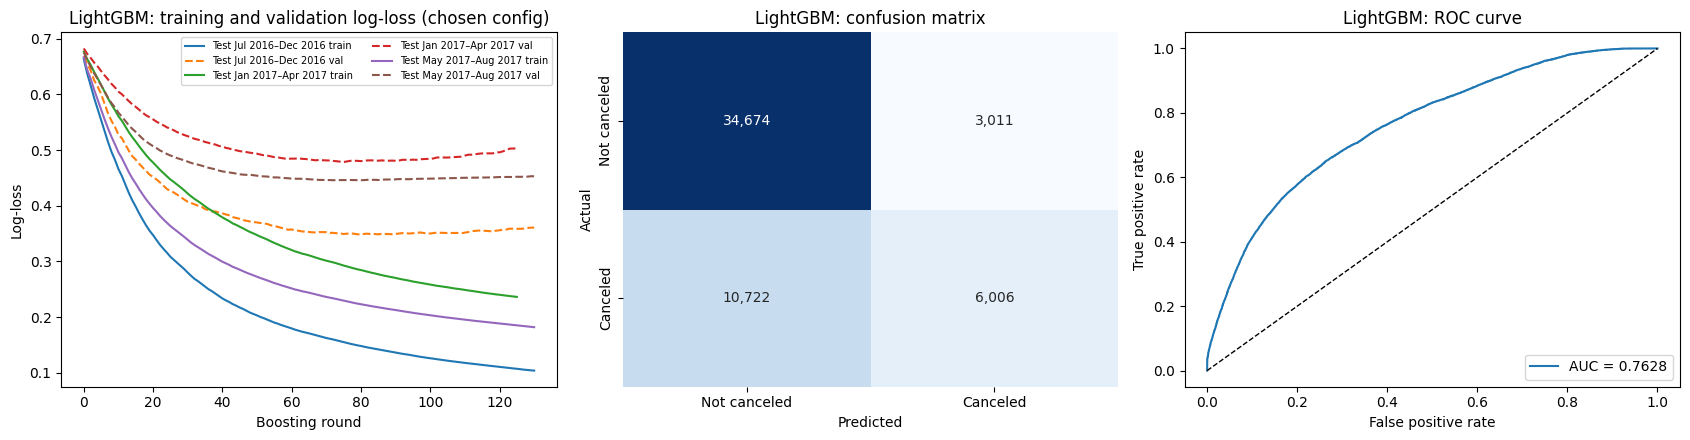

In [20]:
# Cell 19: Evaluate LightGBM
m = 'LightGBM'
tag = 'lightgbm'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for k, hist in enumerate(histories[m]):
    axes[0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
axes[0].set_title(f'{m}: training and validation log-loss (chosen config)')
axes[0].set_xlabel('Boosting round')
axes[0].set_ylabel('Log-loss')
axes[0].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1], axes[2]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 8. Comparison of all models

In [21]:
# Cell 20: Main results table and chosen hyperparameters
results_df = pd.DataFrame(results_rows)
results_df.to_csv(f'{OUT_DIR}/split_results.csv', index=False)
np.save(f'{OUT_DIR}/test_proba.npy', oof_proba)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Fit time of chosen config (s)', 'Search time (s)']
mean_df = results_df.groupby('Model')[metrics].mean().reindex(model_names)
std_df = results_df.groupby('Model')[metrics].std().reindex(model_names)
main_table = mean_df.round(4).astype(str) + ' ± ' + std_df.round(4).astype(str)
for col in ['Fit time of chosen config (s)', 'Search time (s)']:
    main_table[col] = mean_df[col].round(1).astype(str) + ' ± ' + std_df[col].round(1).astype(str)
main_table.to_csv(f'{OUT_DIR}/table_main_results.csv')
print(main_table.to_string())

# chosen hyperparameters per split
chosen_rows = []
for r in results_rows:
    m = r['Model']
    if m == 'Logistic Regression':
        params = {'C': lr_grid[r['Chosen config']]}
    elif m == 'XGBoost':
        params = xgb_configs[r['Chosen config']]
    elif m == 'LightGBM':
        params = lgb_configs[r['Chosen config']]
    else:
        params = dl_configs[r['Chosen config']]
    chosen_rows.append({'Model': m, 'Split': r['Split'], 'Validation ROC-AUC': round(r['Validation ROC-AUC'], 4), **params})
chosen_df = pd.DataFrame(chosen_rows)
chosen_df.to_csv(f'{OUT_DIR}/table_chosen_hyperparameters.csv', index=False)
print('\n=== Chosen hyperparameters per split ===')
print(chosen_df.to_string(index=False))


                            Accuracy        Precision           Recall               F1          ROC-AUC           PR-AUC Fit time of chosen config (s) Search time (s)
Model                                                                                                                                                                  
Logistic Regression  0.7343 ± 0.0258  0.5577 ± 0.0251  0.6685 ± 0.1088  0.6045 ± 0.0393  0.8005 ± 0.0017   0.628 ± 0.0373                     2.6 ± 0.2      12.7 ± 3.3
1D CNN                0.7264 ± 0.017  0.5575 ± 0.0449  0.6129 ± 0.2145  0.5651 ± 0.0985  0.7953 ± 0.0205  0.6252 ± 0.0399                    32.8 ± 6.5    128.3 ± 12.4
DNN                  0.7059 ± 0.0217  0.5251 ± 0.0318  0.6085 ± 0.2797  0.5353 ± 0.1371  0.7735 ± 0.0422  0.6003 ± 0.0732                    24.2 ± 4.5    103.3 ± 14.7
CNN+DNN Hybrid       0.7299 ± 0.0165   0.6019 ± 0.095  0.5205 ± 0.3091   0.502 ± 0.1918  0.7858 ± 0.0358   0.6113 ± 0.067                   54.5 ± 12.5     193.

In [22]:
# Cell 21: Per-class results
report_rows = []
for m in model_names:
    mask = ~np.isnan(oof_proba[m])
    rep = classification_report(y[mask], (oof_proba[m][mask] >= 0.5).astype(int),
                                target_names=['Not canceled', 'Canceled'], output_dict=True)
    for cls in ['Not canceled', 'Canceled']:
        report_rows.append({'Model': m, 'Class': cls, 'Precision': round(rep[cls]['precision'], 4),
                            'Recall': round(rep[cls]['recall'], 4), 'F1': round(rep[cls]['f1-score'], 4),
                            'Support': int(rep[cls]['support'])})
report_df = pd.DataFrame(report_rows)
report_df.to_csv(f'{OUT_DIR}/table_per_class.csv', index=False)
print(report_df.to_string(index=False))


              Model        Class  Precision  Recall     F1  Support
Logistic Regression Not canceled     0.8386  0.7664 0.8008    37685
Logistic Regression     Canceled     0.5592  0.6677 0.6086    16728
             1D CNN Not canceled     0.8131  0.7891 0.8009    37685
             1D CNN     Canceled     0.5545  0.5912 0.5723    16728
                DNN Not canceled     0.8048  0.7626 0.7832    37685
                DNN     Canceled     0.5218  0.5834 0.5509    16728
     CNN+DNN Hybrid Not canceled     0.7845  0.8447 0.8135    37685
     CNN+DNN Hybrid     Canceled     0.5771  0.4772 0.5224    16728
            XGBoost Not canceled     0.7759  0.9030 0.8347    37685
            XGBoost     Canceled     0.6538  0.4125 0.5059    16728
           LightGBM Not canceled     0.7638  0.9201 0.8347    37685
           LightGBM     Canceled     0.6661  0.3590 0.4666    16728


In [23]:
# Cell 22: Statistical tests
f1_matrix = results_df.pivot(index='Split', columns='Model', values='F1')[model_names]
stat, p_friedman = friedmanchisquare(*[f1_matrix[m] for m in model_names])
print(f'Friedman test on F1 across splits: chi2 = {stat:.3f}, p = {p_friedman:.4g}')
dl_models = ['1D CNN', 'DNN', 'CNN+DNN Hybrid']
gb_models = ['XGBoost', 'LightGBM']
best_dl = mean_df.loc[dl_models, 'F1'].idxmax()
best_gb = mean_df.loc[gb_models, 'F1'].idxmax()
mask = ~np.isnan(oof_proba[best_dl])
correct_dl = (oof_proba[best_dl][mask] >= 0.5).astype(int) == y[mask]
correct_gb = (oof_proba[best_gb][mask] >= 0.5).astype(int) == y[mask]
mc_table = [[np.sum(correct_dl & correct_gb), np.sum(correct_dl & ~correct_gb)],
            [np.sum(~correct_dl & correct_gb), np.sum(~correct_dl & ~correct_gb)]]
mc = mcnemar(mc_table, exact=False, correction=True)
print(f'McNemar {best_dl} vs {best_gb}: chi2 = {mc.statistic:.3f}, p = {mc.pvalue:.3g}')
print('[[both correct, only DL correct], [only GB correct, both wrong]] =', np.array(mc_table).tolist())
pd.DataFrame({'Test': ['Friedman (F1, all models)', f'McNemar ({best_dl} vs {best_gb})'],
              'Statistic': [round(stat, 3), round(mc.statistic, 3)], 'p-value': [p_friedman, mc.pvalue],
              'Detail': ['', f'only {best_gb} correct: {mc_table[1][0]}; only {best_dl} correct: {mc_table[0][1]}']}
             ).to_csv(f'{OUT_DIR}/table_statistical_tests.csv', index=False)


Friedman test on F1 across splits: chi2 = 10.619, p = 0.05948
McNemar 1D CNN vs XGBoost: chi2 = 223.376, p = 1.66e-50
[[both correct, only DL correct], [only GB correct, both wrong]] = [[36486, 3143], [4446, 10338]]


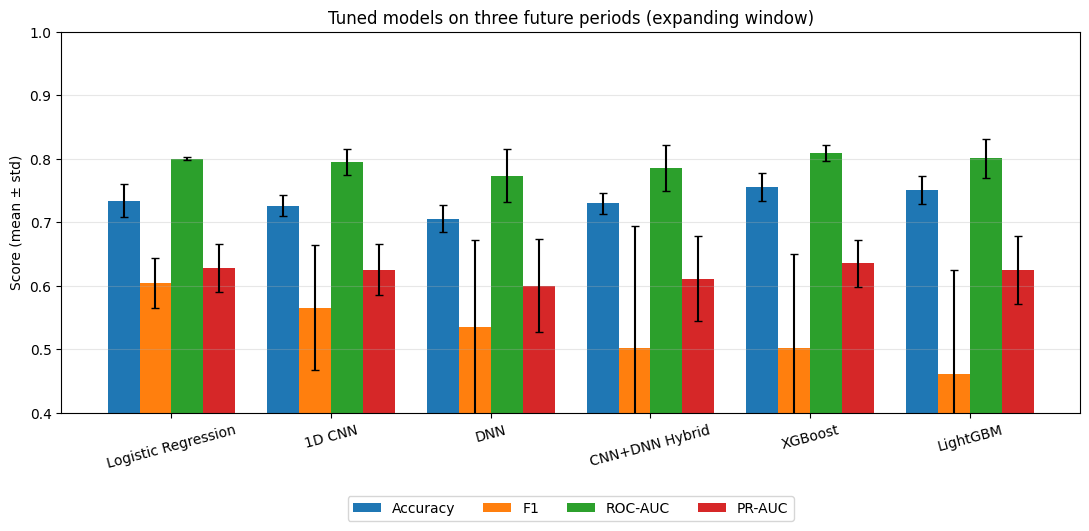

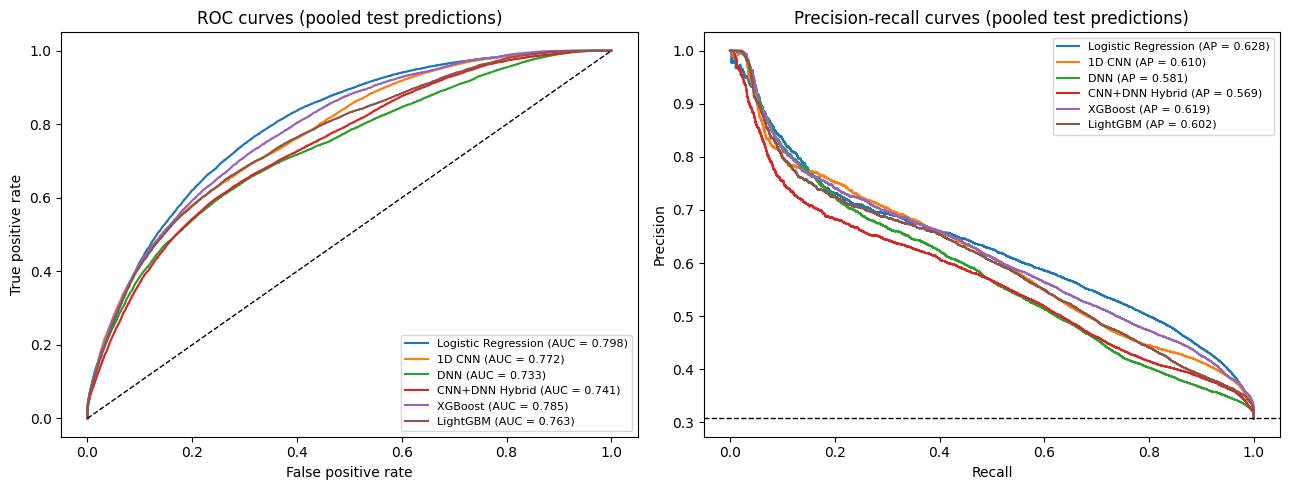

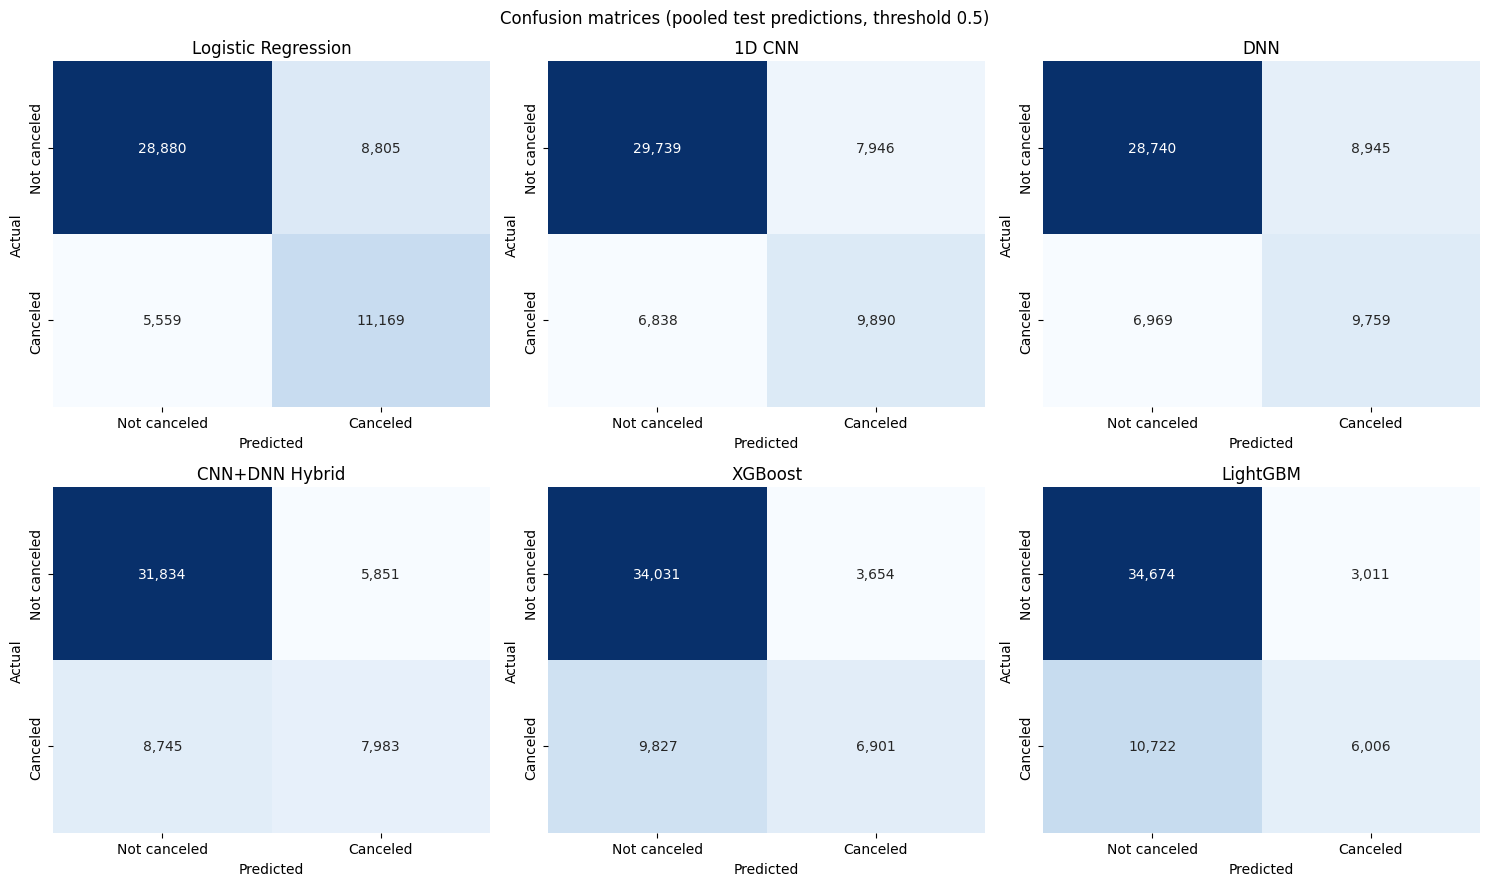

In [24]:
# Cell 23: Figures - comparison, ROC/PR curves, confusion matrices
plot_metrics = ['Accuracy', 'F1', 'ROC-AUC', 'PR-AUC']
fig, ax = plt.subplots(figsize=(11, 5.5))
x_pos = np.arange(len(model_names))
width = 0.2
for i, met in enumerate(plot_metrics):
    ax.bar(x_pos + (i - 1.5) * width, mean_df[met], width, yerr=std_df[met], capsize=3, label=met)
ax.set_xticks(x_pos)
ax.set_xticklabels(model_names, rotation=15)
ax.set_ylim(0.4, 1.0)
ax.set_ylabel('Score (mean ± std)')
ax.set_title('Tuned models on three future periods (expanding window)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_model_comparison.png', dpi=300)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in model_names:
    mask = ~np.isnan(oof_proba[m])
    fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
    axes[0].plot(fpr, tpr, label=f'{m} (AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.3f})')
    prec, rec, _ = precision_recall_curve(y[mask], oof_proba[m][mask])
    axes[1].plot(rec, prec, label=f'{m} (AP = {average_precision_score(y[mask], oof_proba[m][mask]):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curves (pooled test predictions)')
axes[0].legend(fontsize=8)
axes[1].axhline(y[~np.isnan(oof_proba[model_names[0]])].mean(), color='k', ls='--', lw=1)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-recall curves (pooled test predictions)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_roc_pr_curves.png', dpi=300)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, m in zip(axes.ravel(), model_names):
    mask = ~np.isnan(oof_proba[m])
    cm = confusion_matrix(y[mask], (oof_proba[m][mask] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
    ax.set_title(m)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion matrices (pooled test predictions, threshold 0.5)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_confusion_matrices_all.png', dpi=300)
plt.show()


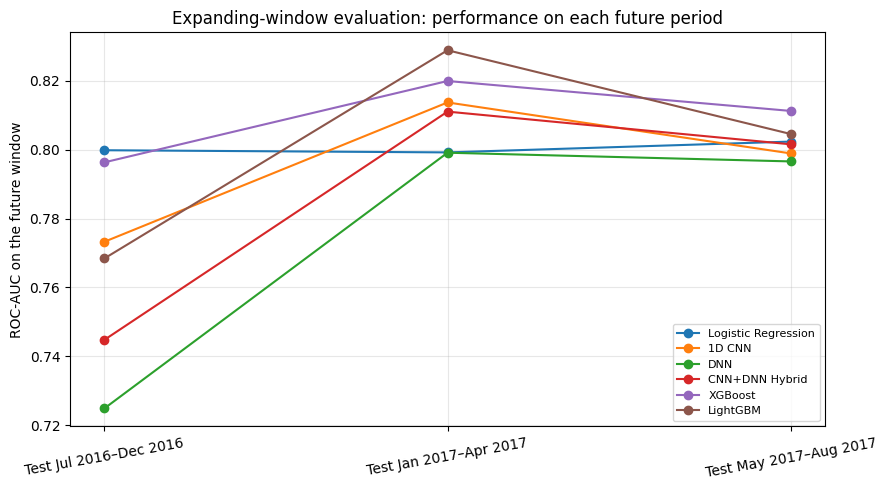

Model                   Logistic Regression  1D CNN     DNN  CNN+DNN Hybrid  XGBoost  LightGBM
Split                                                                                         
Test Jul 2016–Dec 2016               0.7998  0.7733  0.7249          0.7448   0.7963    0.7684
Test Jan 2017–Apr 2017               0.7992  0.8137  0.7991          0.8111   0.8199    0.8289
Test May 2017–Aug 2017               0.8024  0.7989  0.7966          0.8016   0.8113    0.8046


In [25]:
# Cell 24: Performance on each future window
# ROC-AUC per future window, one line per model
pivot_auc = results_df.pivot(index='Split', columns='Model', values='ROC-AUC').reindex(split_names)[model_names]
pivot_auc.to_csv(f'{OUT_DIR}/table_rocauc_by_window.csv')
fig, ax = plt.subplots(figsize=(9, 5))
for m in model_names:
    ax.plot(range(len(split_names)), pivot_auc[m], marker='o', label=m)
ax.set_xticks(range(len(split_names)))
ax.set_xticklabels(split_names, rotation=10)
ax.set_ylabel('ROC-AUC on the future window')
ax.set_title('Expanding-window evaluation: performance on each future period')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_rocauc_by_window.png', dpi=300)
plt.show()
print(pivot_auc.round(4).to_string())
